In [43]:
import torch
from scripts.model import EmbeddingNet
from scripts.data import load_lfw, make_splits, TripletDataset, IMG_SIZE, to_pil_image, get_transforms
import numpy as np
from PIL import Image
import torch.nn.functional as F

In [2]:
MODELS_DIR = "./models"

In [4]:
def load_checkpoint(model_type, num_classes, device):
    ckpt = torch.load(MODELS_DIR + "/" +  f"{model_type}.pt", map_location=device,
                      weights_only=False)
    model = EmbeddingNet().to(device)
    model.load_state_dict(ckpt["state_dict"])
    model.eval()
    return model, ckpt

In [7]:
images, labels, class_names = load_lfw()

In [5]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [9]:
model, _ = load_checkpoint("triplet", len(class_names), device)

In [10]:
sum(p.numel() for p in model.parameters())

11242176

### Image

In [19]:
class_idx_1 = 25
class_idx_2 = 25 # second label-25
class_idx_3 = 9

In [22]:
idx_1 = np.where(labels == class_idx_1)[0][0]
idx_2 = np.where(labels == class_idx_2)[0][1]
idx_3 = np.where(labels == class_idx_3)[0][0]

In [23]:
idx_1, idx_2, idx_3

(np.int64(1), np.int64(13), np.int64(2))

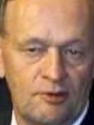

In [26]:
to_pil_image(images[idx_1])

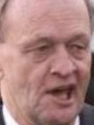

In [27]:
to_pil_image(images[idx_2])

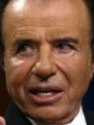

In [29]:
to_pil_image(images[idx_3])

In [31]:
transform = get_transforms(False)

In [36]:
img_1 = transform(Image.fromarray(images[idx_1])).unsqueeze(0).to(device)
img_2 = transform(Image.fromarray(images[idx_2])).unsqueeze(0).to(device)
img_3 = transform(Image.fromarray(images[idx_3])).unsqueeze(0).to(device)

In [37]:
img_1.shape, img_2.shape, img_3.shape

(torch.Size([1, 3, 112, 112]),
 torch.Size([1, 3, 112, 112]),
 torch.Size([1, 3, 112, 112]))

### Inference

In [40]:
model.eval()
pass

In [41]:
with torch.no_grad():
    emb_1 = model(img_1)
    emb_2 = model(img_2)
    emb_3 = model(img_3)

In [42]:
emb_1.shape, emb_2.shape, emb_3.shape

(torch.Size([1, 128]), torch.Size([1, 128]), torch.Size([1, 128]))

In [44]:
sim_12 = F.cosine_similarity(emb_1, emb_2).item()
sim_13 = F.cosine_similarity(emb_1, emb_3).item()
sim_23 = F.cosine_similarity(emb_2, emb_3).item()

print(f"Similarity (1, 2): {sim_12:.4f}")
print(f"Similarity (1, 3): {sim_13:.4f}")
print(f"Similarity (2, 3): {sim_23:.4f}")

Similarity (1, 2): 0.8614
Similarity (1, 3): 0.7970
Similarity (2, 3): 0.5767
